# Анализ отзывов Яндекс Музыки

## Цель

Проверить, как изменились оценки и содержание отзывов после обновления «Моей волны», о котором Яндекс сообщил 19 мая 2026 года.

Источник даты: [официальная новость Яндекса от 19 мая 2026 года](https://yandex.ru/company/news/19-05-2026-01). Обновление распространялось постепенно, поэтому для сравнения выбраны периоды до запуска и после основной волны обновления. Отзывы за переходный период 19–31 мая в сравнение не включены.

## Вопросы исследования

1. Как изменились средняя оценка и доля оценок 1–2 звезды?
2. Стали ли пользователи чаще упоминать интерфейс и навигацию?
3. Какие темы чаще встречаются в отзывах до и после обновления?
4. Одинакова ли динамика в App Store и Google Play?

## Данные

Отзывы хранятся в таблице `public.reviews` базы PostgreSQL. Одна строка соответствует одному отзыву.

В анализе используются площадка (`source`), дата публикации (`review_date`), оценка (`rating`) и текст (`review_text`). Версия приложения используется только при наличии данных.

## План

1. Проверить качество данных.
2. Изучить оценки и количество отзывов во времени.
3. Сравнить два периода.
4. Проверить различия статистическим тестом.
5. Проанализировать тексты отзывов по ключевым словам.
6. Сформулировать выводы.

## Подключение к PostgreSQL

Данные читаются из PostgreSQL с помощью SQL-запросов. Для обработки результатов и построения графиков используются Python, pandas и Matplotlib/Seaborn.


In [2]:
import os
import pandas as pd
from sqlalchemy import create_engine, text

DB_HOST = os.getenv("YA_MUSIC_DB_HOST", "localhost")
DB_PORT = os.getenv("YA_MUSIC_DB_PORT", "5432")
DB_NAME = os.getenv("YA_MUSIC_DB_NAME", "ya_music_analysis")
DB_USER = os.getenv("YA_MUSIC_DB_USER", "postgres")
DB_PASSWORD = os.getenv("PASSWORD")


DATABASE_URL = (
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}"
    f"@{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

engine = create_engine(DATABASE_URL)


In [4]:

with engine.connect() as connection:
    result = connection.execute(text("SELECT 1"))
    print(f"Подключение к PostgreSQL успешно: {result.scalar()}")


Подключение к PostgreSQL успешно: 1


### 5.1. Общая информация о данных

Сначала посмотрим, сколько отзывов находится в таблице и за какой период они собраны.

In [3]:

query = """
SELECT
    COUNT(*) AS total_reviews,
    COUNT(DISTINCT source) AS number_of_sources,
    MIN(review_date) AS first_review_date,
    MAX(review_date) AS last_review_date
FROM public.reviews;
"""

df_overview = pd.read_sql(query, engine)
display(df_overview.style.format({
    "total_reviews": "{:,.0f}",
    "number_of_sources": "{:,.0f}",
}))


,total_reviews,number_of_sources,first_review_date,last_review_date
0,"29,759",2,2025-12-31 19:43:36+00:00,2026-10-11 14:36:06+00:00


In [13]:
print("Значение total_reviews:", df_overview.loc[0, "total_reviews"])
print("Значение number_of_sources:", df_overview.loc[0, "number_of_sources"])

Значение total_reviews: 29759
Значение number_of_sources: 2


### 5.2. Отзывы по площадкам

Сравним объём данных и даты публикации отзывов в App Store и Google Play. Это поможет учитывать различия в размере и временном охвате выборок.

In [8]:

query = """
SELECT
    source,
    COUNT(*) AS total_reviews,
    MIN(review_date) AS first_review_date,
    MAX(review_date) AS last_review_date
FROM public.reviews
GROUP BY source
ORDER BY source;
"""

df_sources = pd.read_sql(query, engine)

display(
    df_sources.style.format({
        "total_reviews": "{:,.0f}",
    })
)

,source,total_reviews,first_review_date,last_review_date
0,App Store,"1,328",2026-01-02 13:25:10+00:00,2026-10-11 11:32:42+00:00
1,Google Play,"28,431",2025-12-31 19:43:36+00:00,2026-10-11 14:36:06+00:00


**Результаты**

В выборке 29 759 отзывов:
- App Store — 1 328;
- Google Play — 28 431.

Большая часть отзывов получена из Google Play. Поэтому далее сравниваем площадки отдельно и используем доли, а не только абсолютные количества. Периоды сбора данных у площадок немного различаются.

## 6. Проверка качества данных

Перед анализом проверим пропуски, дубликаты, диапазон оценок и даты публикации. Эти проверки помогают заметить ошибки, которые могут повлиять на расчёты.

### 6.1. Пропуски в ключевых полях

Проверим, заполнены ли источник, дата, оценка и текст отзыва.

In [17]:

query = """
SELECT
    COUNT(*) AS total_rows,
    COUNT(*) FILTER (WHERE source IS NULL) AS missing_source,
    COUNT(*) FILTER (WHERE review_date IS NULL) AS missing_review_date,
    COUNT(*) FILTER (WHERE rating IS NULL) AS missing_rating,
    COUNT(*) FILTER (WHERE review_text IS NULL) AS missing_review_text,
    COUNT(*) FILTER (
        WHERE review_text IS NOT NULL
          AND TRIM(review_text) = ''
    ) AS empty_review_text
FROM public.reviews;
"""

df_missing = pd.read_sql(query, engine)

print(df_missing.to_string(index=False))


 total_rows  missing_source  missing_review_date  missing_rating  missing_review_text  empty_review_text
      29759               0                    0               0                    0                  0


### 6.2. Дубликаты

Проверим уникальность пары «площадка - идентификатор отзыва». Один и тот же идентификатор на разных площадках не обязательно означает дубликат, поэтому учитываем оба поля.

In [19]:

query = """
SELECT
    COUNT(*) AS total_rows,
    COUNT(DISTINCT (source, review_id)) AS unique_source_review_pairs,
    COUNT(*) - COUNT(DISTINCT (source, review_id)) AS duplicate_pairs
FROM public.reviews;
"""

df_duplicates = pd.read_sql(query, engine)

print(df_duplicates.to_string(index=False))


 total_rows  unique_source_review_pairs  duplicate_pairs
      29759                       29759                0


### 6.3. Корректность оценок

Оценки должны быть целыми числами от 1 до 5. Проверим распределение оценок и наличие значений за пределами этого диапазона.

In [21]:

query = """
SELECT
    rating,
    COUNT(*) AS review_count
FROM public.reviews
GROUP BY rating
ORDER BY rating;
"""

df_rating_quality = pd.read_sql(query, engine)

display(df_rating_quality)


query = """
SELECT
    COUNT(*) FILTER (
        WHERE rating < 1 OR rating > 5
    ) AS invalid_ratings,
    COUNT(*) FILTER (
        WHERE rating IS NULL
    ) AS missing_ratings
FROM public.reviews;
"""

df_invalid_ratings = pd.read_sql(query, engine)

print(df_invalid_ratings.to_string(index=False))



,rating,review_count
0,1,15287
1,2,2964
2,3,2757
3,4,1959
4,5,6792


 invalid_ratings  missing_ratings
               0                0


### 6.4. Даты публикации

Проверим минимальную и максимальную даты и наличие отзывов с датой позже текущего времени.

In [22]:

query = """
SELECT
    MIN(review_date) AS first_review_date,
    MAX(review_date) AS last_review_date,
    COUNT(*) FILTER (
        WHERE review_date > CURRENT_TIMESTAMP
    ) AS future_reviews
FROM public.reviews;
"""

df_date_quality = pd.read_sql(query, engine)

print(df_date_quality.to_string(index=False))


        first_review_date          last_review_date  future_reviews
2025-12-31 19:43:36+00:00 2026-10-11 14:36:06+00:00               0


### 6.5. Результаты проверки

Проверки показали, что в таблице 29 759 отзывов из двух источников. Пропусков в ключевых полях и пустых текстов нет, пары «площадка - идентификатор» уникальны, все оценки находятся в диапазоне от 1 до 5. Отзывов с датой в будущем не обнаружено.

Это подтверждает корректность основных полей, но не гарантирует, что авторы отзывов представляют всех пользователей приложения.

## 7. Разведочный анализ

Сначала посмотрим на объём отзывов, распределение оценок и их динамику по месяцам. Это даст общий контекст для сравнения периодов вокруг обновления.

### 7.1. Количество отзывов по площадкам

Сравним число отзывов из App Store и Google Play. Абсолютные количества также важны: они показывают, насколько различаются объёмы выборок.

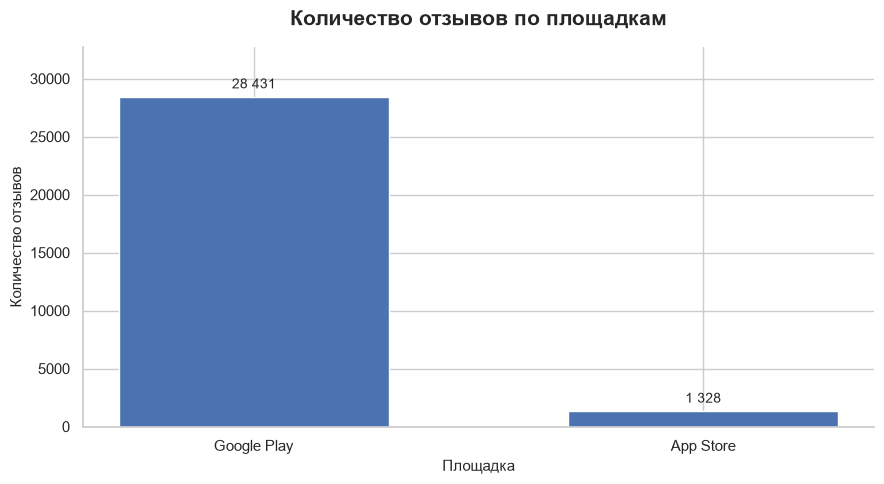

In [23]:

import matplotlib.pyplot as plt
import seaborn as sns

# Единый стиль графиков для проекта
sns.set_theme(style="whitegrid", context="notebook")

# Подготовка данных
df_sources_plot = df_sources.sort_values(
    "total_reviews",
    ascending=False
)

# Построение диаграммы
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    df_sources_plot["source"],
    df_sources_plot["total_reviews"],
    width=0.6
)

# Заголовок и подписи осей
ax.set_title(
    "Количество отзывов по площадкам",
    fontsize=15,
    fontweight="bold",
    pad=16
)
ax.set_xlabel("Площадка", fontsize=11)
ax.set_ylabel("Количество отзывов", fontsize=11)

# Подписи значений над столбцами
ax.bar_label(
    bars,
    labels=[
        f"{value:,.0f}".replace(",", " ")
        for value in df_sources_plot["total_reviews"]
    ],
    padding=4,
    fontsize=10
)

# Убираем верхнюю и правую рамки
sns.despine(ax=ax)

# Немного пространства над столбцами
ax.set_ylim(
    0,
    df_sources_plot["total_reviews"].max() * 1.15
)

plt.tight_layout()
plt.show()


**Интерпретация**

В выборке 28 431 отзыв из Google Play и 1 328 из App Store. Из-за разницы в объёме данных дальше рассматриваем каждую площадку отдельно, а для сравнения частоты событий используем доли.

### 7.2. Распределение оценок

Посмотрим, какие оценки чаще оставляют пользователи на каждой площадке. Это позволит сравнить структуру отзывов, не смешивая данные двух магазинов.

In [24]:

query = """
SELECT
    source,
    rating,
    COUNT(*) AS review_count
FROM public.reviews
GROUP BY source, rating
ORDER BY source, rating;
"""

df_rating_distribution = pd.read_sql(query, engine)

display(df_rating_distribution)


,source,rating,review_count
0,App Store,1,894
1,App Store,2,156
2,App Store,3,145
3,App Store,4,66
4,App Store,5,67
5,Google Play,1,14393
6,Google Play,2,2808
7,Google Play,3,2612
8,Google Play,4,1893
9,Google Play,5,6725


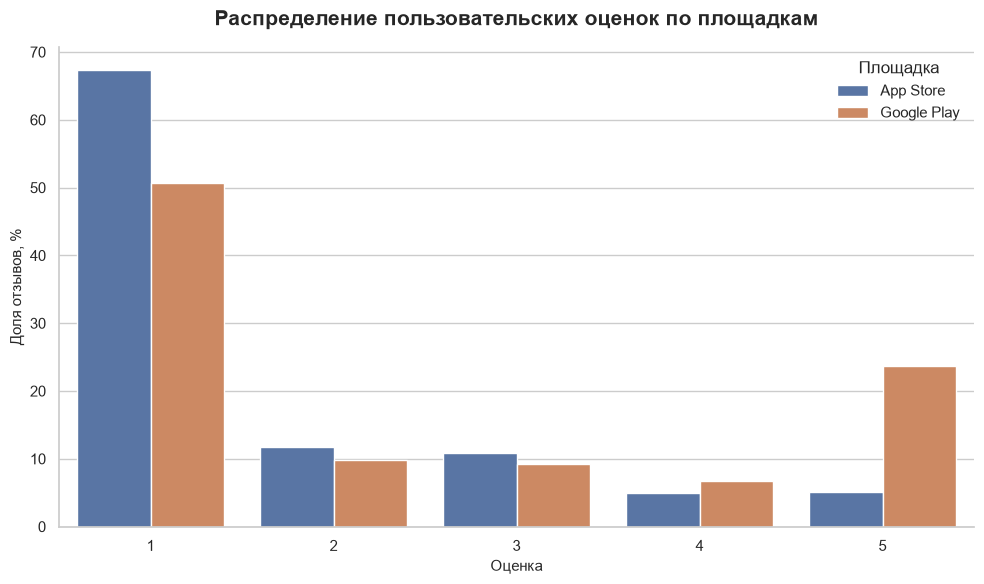

In [25]:

# Рассчитываем долю каждой оценки внутри своей площадки
df_rating_plot = df_rating_distribution.copy()

df_rating_plot["share"] = (
    df_rating_plot["review_count"]
    / df_rating_plot.groupby("source")["review_count"].transform("sum")
    * 100
)

# Строим сравнительную диаграмму
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=df_rating_plot,
    x="rating",
    y="share",
    hue="source",
    ax=ax
)

ax.set_title(
    "Распределение пользовательских оценок по площадкам",
    fontsize=15,
    fontweight="bold",
    pad=16
)
ax.set_xlabel("Оценка", fontsize=11)
ax.set_ylabel("Доля отзывов, %", fontsize=11)

ax.set_xticks([0, 1, 2, 3, 4])
ax.set_xticklabels([1, 2, 3, 4, 5])

ax.legend(title="Площадка", frameon=False)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()


**Интерпретация**

Распределения оценок в App Store и Google Play различаются. Далее посмотрим, как они менялись во времени: общее распределение не показывает, в какой момент появились изменения.

### 7.3. Количество отзывов по месяцам

Посчитаем число отзывов за каждый календарный месяц отдельно для App Store и Google Play. Резкие изменения объёма могут совпадать с обновлениями или другими событиями, но сами по себе не объясняют их причину.

In [26]:

query = """
SELECT
    DATE_TRUNC('month', review_date) AS review_month,
    source,
    COUNT(*) AS review_count
FROM public.reviews
GROUP BY
    DATE_TRUNC('month', review_date),
    source
ORDER BY
    review_month,
    source;
"""

df_monthly_reviews = pd.read_sql(query, engine)

display(df_monthly_reviews.head(12))


,review_month,source,review_count
0,2025-12-31 19:00:00+00:00,App Store,30
1,2025-12-31 19:00:00+00:00,Google Play,2350
2,2026-01-31 19:00:00+00:00,App Store,21
3,2026-01-31 19:00:00+00:00,Google Play,2308
4,2026-02-28 19:00:00+00:00,App Store,129
5,2026-02-28 19:00:00+00:00,Google Play,4441
6,2026-03-31 19:00:00+00:00,App Store,96
7,2026-03-31 19:00:00+00:00,Google Play,2262
8,2026-04-30 19:00:00+00:00,App Store,271
9,2026-04-30 19:00:00+00:00,Google Play,5162


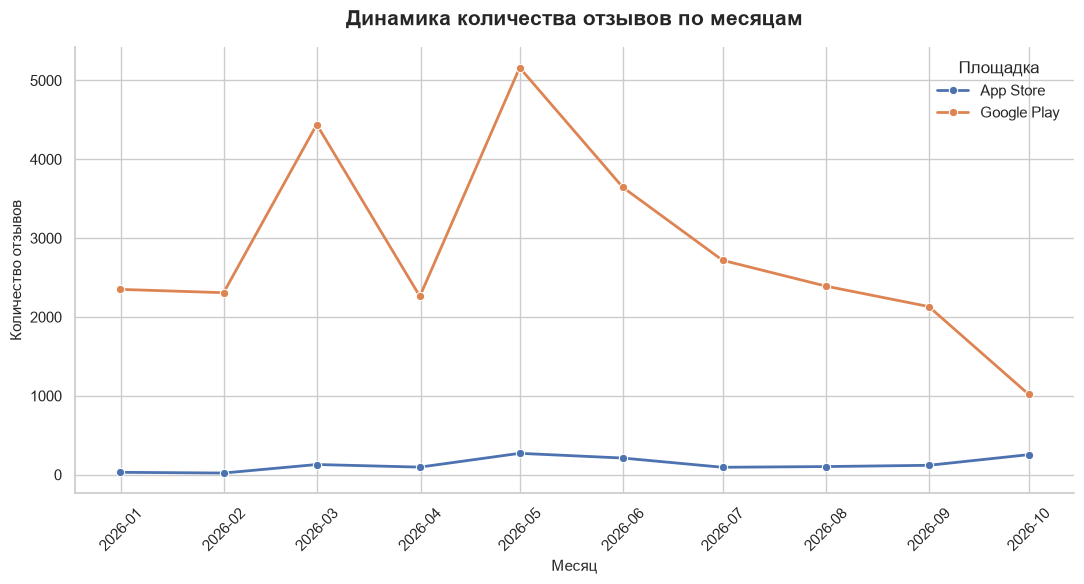

In [27]:
# Строим график динамики количества отзывов по месяцам
fig, ax = plt.subplots(figsize=(11, 6))

sns.lineplot(
    data=df_monthly_reviews,
    x="review_month",
    y="review_count",
    hue="source",
    marker="o",
    linewidth=2,
    ax=ax
)

ax.set_title(
    "Динамика количества отзывов по месяцам",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Месяц", fontsize=11)
ax.set_ylabel("Количество отзывов", fontsize=11)

ax.legend(title="Площадка", frameon=False)
ax.tick_params(axis="x", rotation=45)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### 7.4. Средняя оценка по месяцам

Рассчитаем среднюю оценку за каждый месяц для обеих площадок. Среднее удобно для общей картины, но оно не показывает, как распределены отдельные оценки.

In [28]:
query = """
SELECT
    DATE_TRUNC('month', review_date) AS review_month,
    source,
    COUNT(*) AS review_count,
    ROUND(AVG(rating)::numeric, 2) AS avg_rating
FROM public.reviews
GROUP BY
    DATE_TRUNC('month', review_date),
    source
ORDER BY
    review_month,
    source;
"""

df_monthly_rating = pd.read_sql(query, engine)

display(df_monthly_rating.head(12))

,review_month,source,review_count,avg_rating
0,2025-12-31 19:00:00+00:00,App Store,30,2.40
1,2025-12-31 19:00:00+00:00,Google Play,2350,3.12
2,2026-01-31 19:00:00+00:00,App Store,21,2.05
3,2026-01-31 19:00:00+00:00,Google Play,2308,2.62
4,2026-02-28 19:00:00+00:00,App Store,129,1.43
5,2026-02-28 19:00:00+00:00,Google Play,4441,1.92
6,2026-03-31 19:00:00+00:00,App Store,96,1.80
7,2026-03-31 19:00:00+00:00,Google Play,2262,2.44
8,2026-04-30 19:00:00+00:00,App Store,271,1.56
9,2026-04-30 19:00:00+00:00,Google Play,5162,2.09


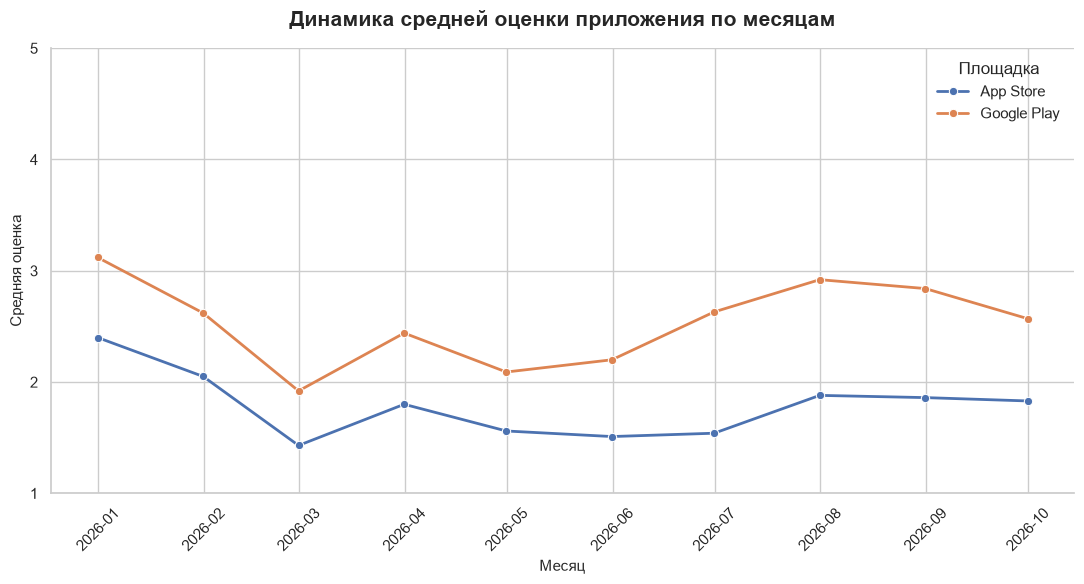

In [29]:
fig, ax = plt.subplots(figsize=(11, 6))

sns.lineplot(
    data=df_monthly_rating,
    x="review_month",
    y="avg_rating",
    hue="source",
    marker="o",
    linewidth=2,
    ax=ax
)

ax.set_title(
    "Динамика средней оценки приложения по месяцам",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Месяц", fontsize=11)
ax.set_ylabel("Средняя оценка", fontsize=11)

# Рейтинг приложения находится в диапазоне от 1 до 5
ax.set_ylim(1, 5)
ax.set_yticks([1, 2, 3, 4, 5])

ax.legend(title="Площадка", frameon=False)
ax.tick_params(axis="x", rotation=45)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### 7.5. Доля низких оценок

Низкими считаем оценки 1 и 2 звезды. Рассчитаем их долю от всех отзывов за месяц для каждой площадки. Доли удобнее сравнивать, чем абсолютные количества при разном объёме данных.

In [30]:
query = """
SELECT
    DATE_TRUNC('month', review_date) AS review_month,
    source,
    COUNT(*) AS review_count,
    COUNT(*) FILTER (
        WHERE rating IN (1, 2)
    ) AS low_rating_count,
    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE rating IN (1, 2)
        ) / COUNT(*),
        2
    ) AS low_rating_share
FROM public.reviews
GROUP BY
    DATE_TRUNC('month', review_date),
    source
ORDER BY
    review_month,
    source;
"""

df_monthly_low_ratings = pd.read_sql(query, engine)

display(df_monthly_low_ratings.head(12))

,review_month,source,review_count,low_rating_count,low_rating_share
0,2025-12-31 19:00:00+00:00,App Store,30,17,56.67
1,2025-12-31 19:00:00+00:00,Google Play,2350,970,41.28
2,2026-01-31 19:00:00+00:00,App Store,21,14,66.67
3,2026-01-31 19:00:00+00:00,Google Play,2308,1259,54.55
4,2026-02-28 19:00:00+00:00,App Store,129,112,86.82
5,2026-02-28 19:00:00+00:00,Google Play,4441,3314,74.62
6,2026-03-31 19:00:00+00:00,App Store,96,71,73.96
7,2026-03-31 19:00:00+00:00,Google Play,2262,1315,58.13
8,2026-04-30 19:00:00+00:00,App Store,271,222,81.92
9,2026-04-30 19:00:00+00:00,Google Play,5162,3602,69.78


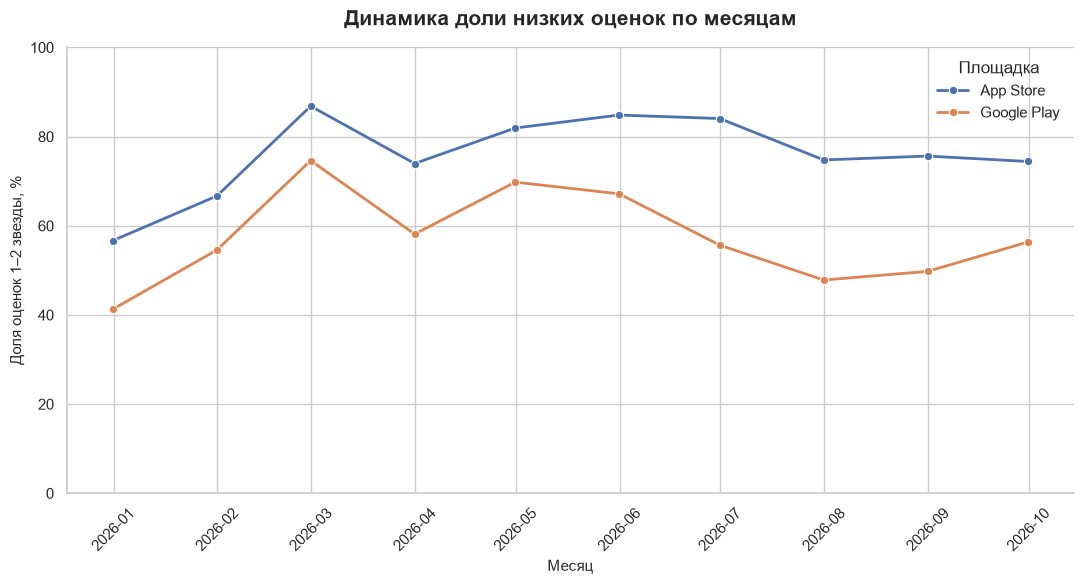

In [31]:
fig, ax = plt.subplots(figsize=(11, 6))

sns.lineplot(
    data=df_monthly_low_ratings,
    x="review_month",
    y="low_rating_share",
    hue="source",
    marker="o",
    linewidth=2,
    ax=ax
)

ax.set_title(
    "Динамика доли низких оценок по месяцам",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Месяц", fontsize=11)
ax.set_ylabel("Доля оценок 1–2 звезды, %", fontsize=11)

ax.set_ylim(0, 100)
ax.legend(title="Площадка", frameon=False)
ax.tick_params(axis="x", rotation=45)

sns.despine(ax=ax)
plt.tight_layout()
plt.show()

**Интерпретация**

В этой выборке самая высокая доля низких оценок приходится на февраль 2026 года: 86,82% в App Store и 74,62% в Google Play. В марте значения снизились, а в апреле и мае снова были высокими.

Чтобы отдельно рассмотреть изменения вокруг обновления, далее сравним два выбранных периода.

## 8. Сравнение периодов до и после обновления

Яндекс сообщил об обновлении «Моей волны» 19 мая 2026 года. В официальном сообщении указано, что обновление будет постепенно доступно пользователям в ближайшие дни ([источник](https://yandex.ru/company/news/19-05-2026-01)).

Для сравнения выбраны два периода:
- **до обновления:** 19 апреля — 18 мая 2026 года;
- **после обновления:** 1–30 июня 2026 года.

Дни с 19 по 31 мая исключены, поскольку в это время обновление постепенно распространялось. Для каждой площадки рассчитаем число отзывов, среднюю оценку, долю оценок 1–2 звезды и долю оценок 4–5 звёзд.

In [32]:
# До обновления: 19 апреля — 18 мая 2026 года (UTC).
# После обновления: 1–30 июня 2026 года (UTC).
# 19–31 мая исключены из-за постепенного распространения обновления.

query = """
WITH labeled_reviews AS (
    SELECT
        source,
        rating,
        CASE
            WHEN review_date >= TIMESTAMPTZ '2026-04-19 00:00:00+00'
             AND review_date <  TIMESTAMPTZ '2026-05-19 00:00:00+00'
                THEN 'До обновления'
            WHEN review_date >= TIMESTAMPTZ '2026-06-01 00:00:00+00'
             AND review_date <  TIMESTAMPTZ '2026-07-01 00:00:00+00'
                THEN 'После обновления'
        END AS period
    FROM public.reviews
    WHERE
        (
            review_date >= TIMESTAMPTZ '2026-04-19 00:00:00+00'
            AND review_date < TIMESTAMPTZ '2026-05-19 00:00:00+00'
        )
        OR
        (
            review_date >= TIMESTAMPTZ '2026-06-01 00:00:00+00'
            AND review_date < TIMESTAMPTZ '2026-07-01 00:00:00+00'
        )
)
SELECT
    source,
    period,
    COUNT(*) AS review_count,
    ROUND(AVG(rating)::numeric, 2) AS avg_rating,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE rating IN (1, 2)) / COUNT(*),
        2
    ) AS low_rating_share,
    ROUND(
        100.0 * COUNT(*) FILTER (WHERE rating IN (4, 5)) / COUNT(*),
        2
    ) AS high_rating_share
FROM labeled_reviews
GROUP BY source, period
ORDER BY source, period;
"""

df_pre_post = pd.read_sql(query, engine)

display(df_pre_post)

,source,period,review_count,avg_rating,low_rating_share,high_rating_share
0,App Store,До обновления,90,1.67,80.00,10.00
1,App Store,После обновления,211,1.52,84.83,5.21
2,Google Play,До обновления,2394,2.53,56.35,32.62
3,Google Play,После обновления,3633,2.20,67.02,23.84


### 8.1. Результаты сравнения

**App Store**
- Количество отзывов выросло с 90 до 211.
- Средняя оценка снизилась с 1,67 до 1,52 (на 0,15 балла).
- Доля оценок 1–2 звезды выросла с 80,00% до 84,83% (+4,83 п. п.).
- Доля оценок 4–5 звёзд снизилась с 10,00% до 5,21% (−4,79 п. п.).

**Google Play**
- Количество отзывов выросло с 2 394 до 3 633.
- Средняя оценка снизилась с 2,53 до 2,20 (на 0,33 балла).
- Доля оценок 1–2 звезды выросла с 56,35% до 67,02% (+10,67 п. п.).
- Доля оценок 4–5 звёзд снизилась с 32,62% до 23,80% (−8,82 п. п.).

В обоих магазинах оценки в июне были ниже, чем в выбранном периоде до обновления. Сильнее изменение выражено в Google Play. Эти данные описывают отзывы в двух периодах и сами по себе не доказывают, что обновление стало единственной причиной изменения оценок.

## 9. Проверка различий в доле низких оценок

Проверим, отличаются ли доли оценок 1–2 звезды между выбранными периодами. Для каждой площадки отдельно используем критерий хи-квадрат Пирсона.

- **H₀:** доли низких оценок в двух периодах одинаковы.
- **H₁:** доли различаются.
- **Уровень значимости:** α = 0,05.

Если p-value меньше 0,05, отвергаем H₀. Тест оценивает различие долей, но не устанавливает причину этого различия.

In [33]:
from scipy.stats import chi2_contingency

query = """
SELECT
    source,
    CASE
        WHEN review_date >= TIMESTAMPTZ '2026-04-19 00:00:00+00'
         AND review_date <  TIMESTAMPTZ '2026-05-19 00:00:00+00'
            THEN 'До обновления'
        WHEN review_date >= TIMESTAMPTZ '2026-06-01 00:00:00+00'
         AND review_date <  TIMESTAMPTZ '2026-07-01 00:00:00+00'
            THEN 'После обновления'
    END AS period,
    COUNT(*) FILTER (
        WHERE rating IN (1, 2)
    ) AS low_rating_count,
    COUNT(*) FILTER (
        WHERE rating NOT IN (1, 2)
    ) AS other_rating_count
FROM public.reviews
WHERE
    (
        review_date >= TIMESTAMPTZ '2026-04-19 00:00:00+00'
        AND review_date < TIMESTAMPTZ '2026-05-19 00:00:00+00'
    )
    OR
    (
        review_date >= TIMESTAMPTZ '2026-06-01 00:00:00+00'
        AND review_date < TIMESTAMPTZ '2026-07-01 00:00:00+00'
    )
GROUP BY source, period
ORDER BY source, period;
"""

df_test_data = pd.read_sql(query, engine)

display(df_test_data)

,source,period,low_rating_count,other_rating_count
0,App Store,До обновления,72,18
1,App Store,После обновления,179,32
2,Google Play,До обновления,1349,1045
3,Google Play,После обновления,2435,1198


In [34]:
results = []

for source in df_test_data["source"].unique():
    source_data = df_test_data[
        df_test_data["source"] == source
    ].set_index("period")

    before = source_data.loc["До обновления"]
    after = source_data.loc["После обновления"]

    contingency_table = [
        [
            int(before["low_rating_count"]),
            int(before["other_rating_count"])
        ],
        [
            int(after["low_rating_count"]),
            int(after["other_rating_count"])
        ]
    ]

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table,
        correction=False
    )

    results.append({
        "source": source,
        "chi2_statistic": chi2,
        "p_value": p_value,
        "significant_at_0.05": p_value < 0.05
    })

df_significance = pd.DataFrame(results)

display(
    df_significance.style.format({
        "chi2_statistic": "{:.3f}",
        "p_value": "{:.8f}"
    })
)

,source,chi2_statistic,p_value,significant_at_0.05
0,App Store,1.064,0.30222587,False
1,Google Play,70.383,0.00000000,True


### 9.1. Результаты теста

**App Store**

χ² = 1,064; p-value = 0,3022. Значение p-value выше 0,05, поэтому статистически значимое различие не выявлено. Доля низких оценок выросла с 80,00% до 84,83%, но имеющихся данных недостаточно, чтобы считать этот рост статистически значимым на выбранном уровне.

**Google Play**

χ² = 70,383; p-value < 0,001. Доля низких оценок выросла с 56,35% до 67,02%; различие статистически значимо при α = 0,05.

Таким образом, статистически значимое увеличение доли низких оценок обнаружено в Google Play, но не в App Store.

## 10. Анализ текстов отзывов

Теперь посмотрим, как часто пользователи упоминают интерфейс. На первом этапе используем словарь ключевых слов, связанных с дизайном и навигацией, и посчитаем долю отзывов с такими словами.

Совпадение по ключевому слову не обязательно означает жалобу: слово может встречаться и в положительном или нейтральном отзыве.

In [35]:
interface_keywords = [
    "интерфейс",
    "дизайн",
    "оформление",
    "навигация",
    "меню",
    "кнопка",
    "кнопки",
    "вкладка",
    "вкладки",
    "экран",
    "экраны",
    "расположение",
    "неудобно",
    "неудобный",
    "неудобная",
    "неудобное",
    "interface",
    "design",
    "layout",
    "navigation",
    "button",
    "buttons",
    "menu"
]

print(f"Количество ключевых слов: {len(interface_keywords)}")

Количество ключевых слов: 23


In [36]:
query = """
SELECT
    source,
    review_date,
    rating,
    review_text,
    CASE
        WHEN review_date >= TIMESTAMPTZ '2026-04-19 00:00:00+00'
         AND review_date <  TIMESTAMPTZ '2026-05-19 00:00:00+00'
            THEN 'До обновления'
        WHEN review_date >= TIMESTAMPTZ '2026-06-01 00:00:00+00'
         AND review_date <  TIMESTAMPTZ '2026-07-01 00:00:00+00'
            THEN 'После обновления'
    END AS period
FROM public.reviews
WHERE
    (
        review_date >= TIMESTAMPTZ '2026-04-19 00:00:00+00'
        AND review_date < TIMESTAMPTZ '2026-05-19 00:00:00+00'
    )
    OR
    (
        review_date >= TIMESTAMPTZ '2026-06-01 00:00:00+00'
        AND review_date < TIMESTAMPTZ '2026-07-01 00:00:00+00'
    )
ORDER BY review_date;
"""

df_text_reviews = pd.read_sql(query, engine)

print(f"Количество загруженных отзывов: {len(df_text_reviews):,}")
display(df_text_reviews.head())

Количество загруженных отзывов: 6,328


,source,review_date,rating,review_text,period
0,Google Play,2026-04-19 00:57:45+00:00,5,отлично спасибо,До обновления
1,Google Play,2026-04-19 03:32:33+00:00,1,скинул ссылку на песню другу и она не открывае...,До обновления
2,Google Play,2026-04-19 03:35:15+00:00,2,"Всё хорошо, но с недавних пор начали попадатьс...",До обновления
3,Google Play,2026-04-19 03:53:41+00:00,1,Теперь ограничения добрались и до музыки... Ка...,До обновления
4,Google Play,2026-04-19 04:09:41+00:00,1,воспроизведение музыки из плейлиста останавлив...,До обновления


In [37]:
import re

# Объединяем ключевые слова в один шаблон поиска
interface_pattern = re.compile(
    r"\b(?:" + "|".join(
        re.escape(word) for word in interface_keywords
    ) + r")\b",
    flags=re.IGNORECASE
)

# Приводим текст к строковому типу и ищем совпадения
df_text_reviews["review_text_clean"] = (
    df_text_reviews["review_text"]
    .fillna("")
    .astype(str)
    .str.lower()
)

df_text_reviews["mentions_interface"] = (
    df_text_reviews["review_text_clean"]
    .apply(lambda text: bool(interface_pattern.search(text)))
)

print("Количество отзывов:", len(df_text_reviews))
print(
    "Отзывов с упоминанием интерфейса:",
    int(df_text_reviews["mentions_interface"].sum())
)

Количество отзывов: 6328
Отзывов с упоминанием интерфейса: 1454


In [38]:
df_interface_mentions = (
    df_text_reviews
    .groupby(["source", "period"], as_index=False)
    .agg(
        review_count=("review_text", "size"),
        interface_mentions=("mentions_interface", "sum")
    )
)

df_interface_mentions["interface_share"] = (
    100
    * df_interface_mentions["interface_mentions"]
    / df_interface_mentions["review_count"]
)

display(
    df_interface_mentions.style.format({
        "review_count": "{:,.0f}",
        "interface_mentions": "{:,.0f}",
        "interface_share": "{:.2f}%"
    })
)

,source,period,review_count,interface_mentions,interface_share
0,App Store,До обновления,90,17,18.89%
1,App Store,После обновления,211,78,36.97%
2,Google Play,До обновления,"2,394",367,15.33%
3,Google Play,После обновления,"3,633",992,27.31%


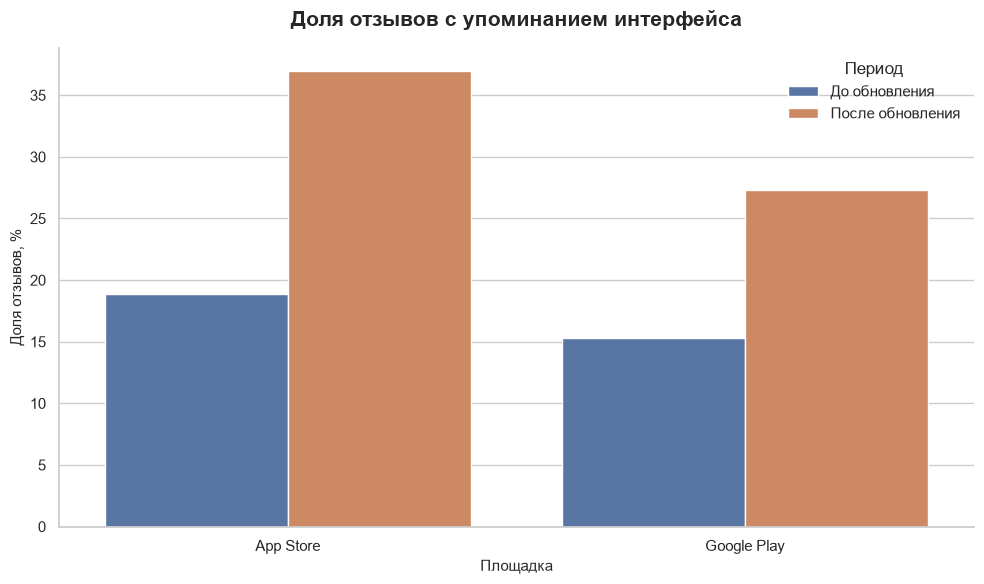

In [39]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=df_interface_mentions,
    x="source",
    y="interface_share",
    hue="period",
    ax=ax
)

ax.set_title(
    "Доля отзывов с упоминанием интерфейса",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Площадка", fontsize=11)
ax.set_ylabel("Доля отзывов, %", fontsize=11)

ax.legend(title="Период", frameon=False)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

### 10.1. Упоминания интерфейса по первоначальному словарю

По первоначальному словарю ключевых слов упоминания интерфейса найдены:

**App Store**
- до обновления — 17 из 90 отзывов (18,89%);
- после обновления — 78 из 211 (36,97%);
- изменение — +18,08 п. п.

**Google Play**
- до обновления — 367 из 2 394 отзывов (15,33%);
- после обновления — 992 из 3 633 (27,31%);
- изменение — +11,98 п. п.

На обеих площадках такие слова встречаются в июне чаще, чем в выбранном периоде до обновления. Это частота совпадений со словарём, а не точный подсчёт жалоб.

In [40]:
df_interface_examples = (
    df_text_reviews[
        df_text_reviews["mentions_interface"]
    ][
        [
            "source",
            "period",
            "rating",
            "review_text"
        ]
    ]
    .sample(
        n=min(20, int(df_text_reviews["mentions_interface"].sum())),
        random_state=42
    )
    .sort_values(["source", "period"])
    .reset_index(drop=True)
)

display(df_interface_examples)

,source,period,rating,review_text
0,App Store,После обновления,1,"Интерфейс. Верните старый интерфейс, после обн..."
1,Google Play,До обновления,3,Приложением пользуюсь очень давно.Верните обра...
2,Google Play,До обновления,1,Новый дизайн просто отвратителен
3,Google Play,До обновления,1,Много музыки урезано/запикано. В последней вер...
4,Google Play,После обновления,3,"верните преждний интерфейс , или сделайте возм..."
5,Google Play,После обновления,2,ладно давно стерпели что сервис кастрирован от...
6,Google Play,После обновления,2,Верните прежний дизайн моей волны! ну невозмож...
7,Google Play,После обновления,3,"Новый дизайн - это просто сон собаки, нужна ин..."
8,Google Play,После обновления,1,за новый дизайн
9,Google Play,После обновления,1,Очень классное и удобное приложение. Денег за ...


### 10.2. Расширенный словарь

В примерах отзывов встречались выражения о редизайне, прежнем оформлении, «Моей волне» и удалённых кнопках. Добавим эти формулировки в словарь, чтобы находить больше релевантных упоминаний.

После расширения словаря доли нельзя напрямую сравнивать с результатами первоначального поиска: набор ключевых слов изменился.

In [41]:
interface_keywords_extended = [
    "интерфейс",
    "дизайн",
    "редизайн",
    "оформление",
    "навигация",
    "меню",
    "кнопка",
    "кнопки",
    "вкладка",
    "вкладки",
    "экран",
    "экраны",
    "расположение",
    "неудобно",
    "неудобный",
    "неудобная",
    "неудобное",
    "прежний интерфейс",
    "старый интерфейс",
    "старый дизайн",
    "новый дизайн",
    "верните старый",
    "верните прежний",
    "убрали кнопку",
    "убрали кнопки",
    "моя волна",
    "interface",
    "design",
    "redesign",
    "layout",
    "navigation",
    "button",
    "buttons",
    "menu"
]

interface_pattern_extended = re.compile(
    "|".join(
        re.escape(word)
        for word in sorted(
            interface_keywords_extended,
            key=len,
            reverse=True
        )
    ),
    flags=re.IGNORECASE
)

df_text_reviews["mentions_interface_extended"] = (
    df_text_reviews["review_text_clean"]
    .apply(
        lambda text: bool(
            interface_pattern_extended.search(text)
        )
    )
)

print(
    "Упоминаний по первоначальному словарю:",
    int(df_text_reviews["mentions_interface"].sum())
)

print(
    "Упоминаний по расширенному словарю:",
    int(df_text_reviews["mentions_interface_extended"].sum())
)

Упоминаний по первоначальному словарю: 1454
Упоминаний по расширенному словарю: 1911


In [42]:
df_interface_extended = (
    df_text_reviews
    .groupby(["source", "period"], as_index=False)
    .agg(
        review_count=("review_text", "size"),
        interface_mentions=(
            "mentions_interface_extended",
            "sum"
        )
    )
)

df_interface_extended["interface_share"] = (
    100
    * df_interface_extended["interface_mentions"]
    / df_interface_extended["review_count"]
)

display(
    df_interface_extended.style.format({
        "review_count": "{:,.0f}",
        "interface_mentions": "{:,.0f}",
        "interface_share": "{:.2f}%"
    })
)

,source,period,review_count,interface_mentions,interface_share
0,App Store,До обновления,90,22,24.44%
1,App Store,После обновления,211,100,47.39%
2,Google Play,До обновления,"2,394",503,21.01%
3,Google Play,После обновления,"3,633","1,286",35.40%


### 10.3. Низкие оценки и упоминания интерфейса

Отдельно выделим отзывы, в которых одновременно есть совпадение с расширенным словарём и оценка 1 или 2 звезды. Этот показатель не равен числу жалоб именно на интерфейс: низкая оценка может быть связана и с другой проблемой приложения.

In [43]:
df_text_reviews["low_rating"] = (
    df_text_reviews["rating"].isin([1, 2])
)

df_text_reviews["negative_interface_review"] = (
    df_text_reviews["mentions_interface_extended"]
    & df_text_reviews["low_rating"]
)

df_negative_interface = (
    df_text_reviews
    .groupby(["source", "period"], as_index=False)
    .agg(
        review_count=("review_text", "size"),
        interface_mentions=(
            "mentions_interface_extended",
            "sum"
        ),
        negative_interface_mentions=(
            "negative_interface_review",
            "sum"
        )
    )
)

df_negative_interface["negative_interface_share"] = (
    100
    * df_negative_interface["negative_interface_mentions"]
    / df_negative_interface["review_count"]
)

display(
    df_negative_interface.style.format({
        "review_count": "{:,.0f}",
        "interface_mentions": "{:,.0f}",
        "negative_interface_mentions": "{:,.0f}",
        "negative_interface_share": "{:.2f}%"
    })
)

,source,period,review_count,interface_mentions,negative_interface_mentions,negative_interface_share
0,App Store,До обновления,90,22,21,23.33%
1,App Store,После обновления,211,100,86,40.76%
2,Google Play,До обновления,"2,394",503,345,14.41%
3,Google Play,После обновления,"3,633","1,286","1,038",28.57%


### 10.4. Доля низко оценённых отзывов с упоминанием интерфейса

**App Store**
- до обновления — 21 из 90 отзывов (23,33%);
- после обновления — 86 из 211 (40,76%);
- изменение — +17,43 п. п.

**Google Play**
- до обновления — 345 из 2 394 отзывов (14,41%);
- после обновления — 1 038 из 3 633 (28,57%);
- изменение — +14,16 п. п.

В июне доля отзывов с низкой оценкой и упоминанием интерфейса была выше на обеих площадках. Поскольку отбор основан на словаре и общей оценке, результат следует трактовать как приближённый показатель, а не как точное число негативных отзывов о редизайне.

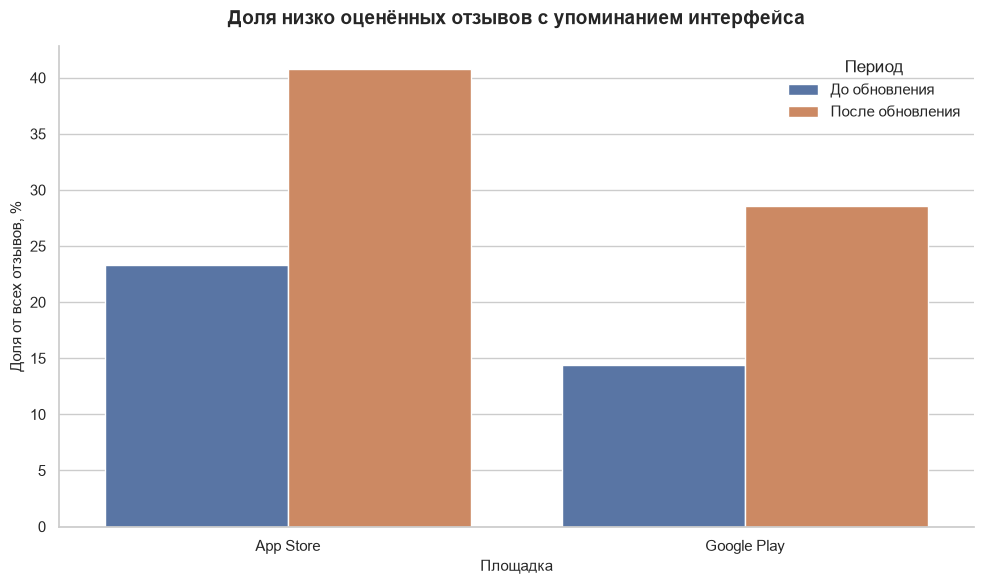

In [44]:
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=df_negative_interface,
    x="source",
    y="negative_interface_share",
    hue="period",
    ax=ax
)

ax.set_title(
    "Доля низко оценённых отзывов с упоминанием интерфейса",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Площадка", fontsize=11)
ax.set_ylabel("Доля от всех отзывов, %", fontsize=11)

ax.legend(title="Период", frameon=False)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

### 10.5. Статистическая проверка

Проверим различия в доле отзывов с низкой оценкой и упоминанием интерфейса. Для каждой площадки сравним эту группу со всеми остальными отзывами с помощью критерия хи-квадрат Пирсона.

- **H₀:** доли в двух периодах одинаковы.
- **H₁:** доли различаются.
- **Уровень значимости:** α = 0,05.

In [45]:
from scipy.stats import chi2_contingency

significance_results = []

for source in df_text_reviews["source"].unique():
    source_data = df_text_reviews[
        df_text_reviews["source"] == source
    ]

    before = source_data[
        source_data["period"] == "До обновления"
    ]

    after = source_data[
        source_data["period"] == "После обновления"
    ]

    before_negative = int(
        before["negative_interface_review"].sum()
    )
    after_negative = int(
        after["negative_interface_review"].sum()
    )

    before_other = len(before) - before_negative
    after_other = len(after) - after_negative

    contingency_table = [
        [before_negative, before_other],
        [after_negative, after_other]
    ]

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    significance_results.append({
        "source": source,
        "before_share": (
            100 * before_negative / len(before)
        ),
        "after_share": (
            100 * after_negative / len(after)
        ),
        "chi2": chi2,
        "p_value": p_value,
        "significant": p_value < 0.05
    })

df_significance_interface = pd.DataFrame(
    significance_results
)

display(
    df_significance_interface.style.format({
        "before_share": "{:.2f}%",
        "after_share": "{:.2f}%",
        "chi2": "{:.3f}",
        "p_value": "{:.6g}"
    })
)

,source,before_share,after_share,chi2,p_value,significant
0,Google Play,14.41%,28.57%,162.854,2.6917e-37,True
1,App Store,23.33%,40.76%,7.618,0.00578016,True


### 10.6. Результаты статистической проверки

**Google Play**

Доля выросла с 14,41% до 28,57%. χ² = 162,854; p-value ≈ 2,69 × 10⁻³⁷. Различие статистически значимо при α = 0,05.

**App Store**

Доля выросла с 23,33% до 40,76%. χ² = 7,618; p-value ≈ 0,0058. Различие также статистически значимо при α = 0,05.

В обоих магазинах доля отзывов, которые одновременно имеют оценку 1–2 звезды и содержат слова из расширенного словаря, выросла. Это не означает, что каждый такой отзыв посвящён редизайну: классификация не учитывает контекст текста.

## 11. Другие темы в отзывах

Проверим, как часто в текстах встречаются слова, связанные с воспроизведением музыки, поиском и рекомендациями, подпиской, рекламой и техническими сбоями. Один отзыв может содержать слова сразу из нескольких категорий.

Категории определяются словарями ключевых слов. Результаты показывают частоту таких упоминаний, а не подтверждённое количество отдельных неисправностей или жалоб.

In [47]:
problem_categories = {
    "Интерфейс и навигация": [
        "интерфейс", "дизайн", "редизайн", "оформление",
        "навигация", "меню", "кнопка", "вкладка",
        "экран", "моя волна", "верните старый",
        "верните прежний", "убрали кнопку"
    ],
    "Воспроизведение музыки": [
        "не играет", "не воспроизводится", "не включается",
        "останавливается", "прерывается", "плеер",
        "переключает треки", "не грузит музыку"
    ],
    "Поиск и рекомендации": [
        "поиск", "не находит", "рекомендации",
        "моя волна", "плейлист", "подборка"
    ],
    "Подписка и оплата": [
        "подписка", "оплата", "списали деньги",
        "платёж", "платеж", "плюс", "дорого",
        "не могу оформить"
    ],
    "Реклама": [
        "реклама", "рекламный", "рекламу"
    ],
    "Технические сбои": [
        "ошибка", "вылетает", "вылет", "зависает",
        "не работает", "сбой", "не открывается",
        "тормозит", "баг", "краш"
    ]
}

In [48]:
# Отмечаем, какие категории упоминаются в каждом отзыве.

for category, keywords in problem_categories.items():
    pattern = re.compile(
        "|".join(
            re.escape(keyword)
            for keyword in sorted(keywords, key=len, reverse=True)
        ),
        flags=re.IGNORECASE
    )

    df_text_reviews[category] = (
        df_text_reviews["review_text_clean"]
        .apply(lambda text: bool(pattern.search(text)))
    )

# Считаем упоминания по площадке и периоду.
category_results = []

for category in problem_categories:
    grouped = (
        df_text_reviews
        .groupby(["source", "period"], as_index=False)
        .agg(
            review_count=("review_text", "size"),
            mentions=(category, "sum")
        )
    )

    grouped["category"] = category
    grouped["share"] = (
        100 * grouped["mentions"] / grouped["review_count"]
    )

    category_results.append(grouped)

df_category_analysis = pd.concat(
    category_results,
    ignore_index=True
)

display(
    df_category_analysis[
        [
            "source",
            "period",
            "category",
            "review_count",
            "mentions",
            "share"
        ]
    ].sort_values(
        ["source", "category", "period"]
    ).style.format({
        "review_count": "{:,.0f}",
        "mentions": "{:,.0f}",
        "share": "{:.2f}%"
    })
)

,source,period,category,review_count,mentions,share
4,App Store,До обновления,Воспроизведение музыки,90,0,0.00%
5,App Store,После обновления,Воспроизведение музыки,211,3,1.42%
0,App Store,До обновления,Интерфейс и навигация,90,18,20.00%
1,App Store,После обновления,Интерфейс и навигация,211,89,42.18%
12,App Store,До обновления,Подписка и оплата,90,9,10.00%
13,App Store,После обновления,Подписка и оплата,211,13,6.16%
8,App Store,До обновления,Поиск и рекомендации,90,11,12.22%
9,App Store,После обновления,Поиск и рекомендации,211,33,15.64%
16,App Store,До обновления,Реклама,90,1,1.11%
17,App Store,После обновления,Реклама,211,3,1.42%


### 11.1. Сравнение категорий

**Интерфейс и навигация**

Доля отзывов с соответствующими словами выросла:
- Google Play — с 18,55% до 32,29% (+13,74 п. п.);
- App Store — с 20,00% до 42,18% (+22,18 п. п.).

**Поиск и рекомендации**

- Google Play — с 12,70% до 13,13%;
- App Store — с 12,22% до 15,64%.

**Подписка и оплата**

- Google Play — с 6,39% до 5,42%;
- App Store — с 10,00% до 6,16%.

**Технические сбои и воспроизведение**

В Google Play доля упоминаний технических сбоев снизилась с 4,89% до 4,29%, а упоминаний проблем воспроизведения выросла с 2,38% до 2,84%.

В App Store упоминания проблем воспроизведения выросли с 0 до 3 отзывов, а доля упоминаний технических сбоев снизилась с 11,11% до 9,48%.

**Реклама**

Доля упоминаний рекламы выросла с 1,21% до 2,31% в Google Play и с 1,11% до 1,42% в App Store.

Самое заметное изменение — рост упоминаний интерфейса и навигации. Эти категории пересекаются и основаны на словах в тексте, поэтому их нельзя считать взаимоисключающими типами проблем.

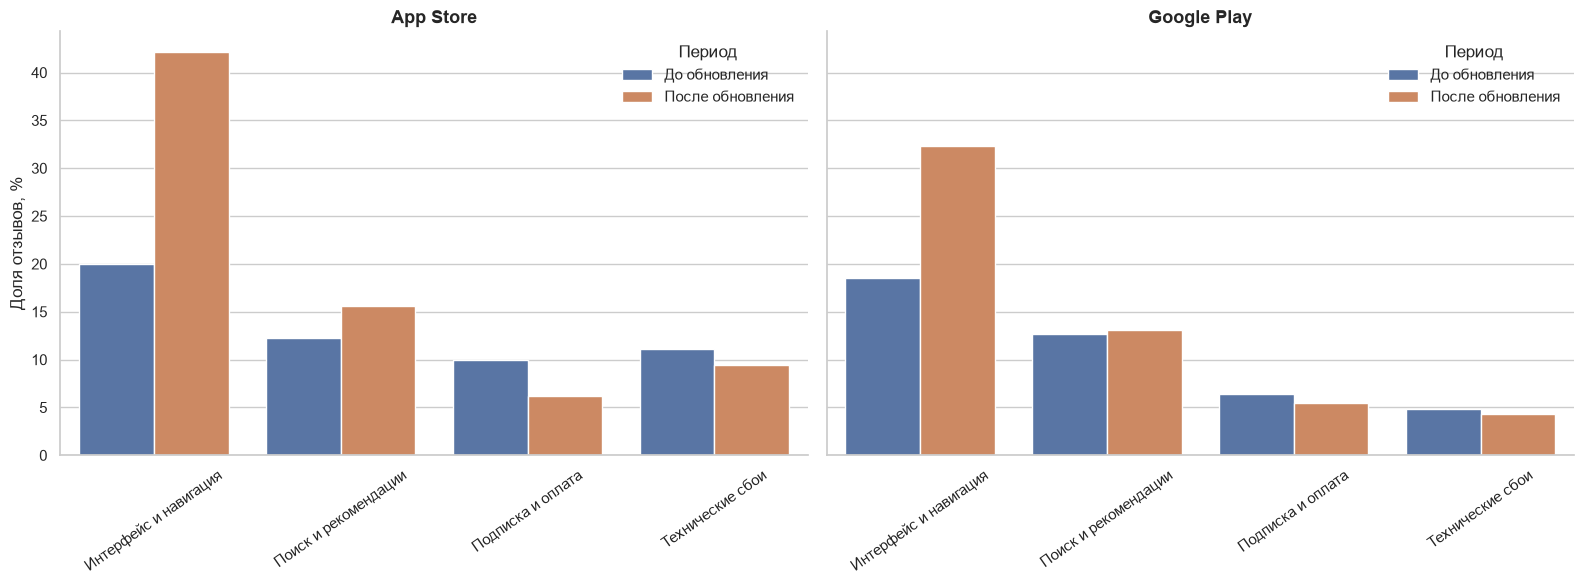

In [49]:
categories_to_plot = [
    "Интерфейс и навигация",
    "Поиск и рекомендации",
    "Подписка и оплата",
    "Технические сбои"
]

plot_data = df_category_analysis[
    df_category_analysis["category"].isin(categories_to_plot)
].copy()

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 6),
    sharey=True
)

for ax, source in zip(
    axes,
    ["App Store", "Google Play"]
):
    source_data = plot_data[
        plot_data["source"] == source
    ]

    sns.barplot(
        data=source_data,
        x="category",
        y="share",
        hue="period",
        ax=ax
    )

    ax.set_title(source, fontsize=13, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Доля отзывов, %")
    ax.tick_params(axis="x", rotation=35)
    ax.legend(title="Период", frameon=False)

sns.despine()
plt.tight_layout()
plt.show()

## 12. Выводы

В работе проанализированы 29 759 отзывов Яндекс Музыки из App Store и Google Play. Сравнивались отзывы за 19 апреля — 18 мая и 1–30 июня 2026 года; обновление «Моей волны» было объявлено 19 мая 2026 года ([официальное сообщение Яндекса](https://yandex.ru/company/news/19-05-2026-01)).

### Оценки

В Google Play средняя оценка снизилась с 2,53 до 2,20, а доля оценок 1–2 звезды выросла с 56,35% до 67,02%. В App Store средняя оценка снизилась с 1,67 до 1,52, а доля низких оценок выросла с 80,00% до 84,83%.

По критерию хи-квадрат увеличение доли низких оценок статистически значимо в Google Play (p < 0,001). В App Store статистически значимого различия не выявлено (p = 0,3022).

### Упоминания интерфейса

По расширенному словарю доля отзывов с упоминанием интерфейса выросла с 21,01% до 35,40% в Google Play и с 24,44% до 47,39% в App Store.

Доля отзывов с оценкой 1–2 звезды и словами из расширенного словаря также выросла: с 14,41% до 28,57% в Google Play и с 23,33% до 40,76% в App Store. Различия статистически значимы на обеих площадках (p < 0,05).

### Другие темы

Среди категорий, выделенных по ключевым словам, сильнее всего выросла частота упоминаний интерфейса и навигации. Динамика остальных категорий была менее выраженной: доля упоминаний подписки и оплаты снизилась, а упоминания рекламы и проблем воспроизведения немного выросли в Google Play.

### Ограничения

- Словари ищут слова и выражения, но не определяют смысл отзыва. Поэтому найденные упоминания нельзя считать точным числом жалоб.
- Отзывы оставляют не все пользователи приложения; их оценки не обязательно отражают мнение всей аудитории.
- Сравнение двух периодов показывает различия во времени, но не доказывает, что их вызвало именно обновление. На оценки могли повлиять другие изменения сервиса и состав авторов отзывов.

### Итог

В июне 2026 года оценки в отзывах были ниже, а упоминания интерфейса встречались чаще, чем в выбранном периоде до обновления. Особенно заметно выросла доля отзывов с низкой оценкой и упоминанием интерфейса. Эти результаты указывают на негативную реакцию части авторов отзывов, но для точной оценки причин нужно учитывать контекст конкретных отзывов и другие изменения сервиса.